In [ ]:

# 1. ربط جوجل درايف
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import networkx as nx
from itertools import combinations

import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
import time

print("1. جاري قراءةالبيانات كاملة...")
base_path = "/content/drive/MyDrive/ieee_data/"
df_txn = pd.read_csv(base_path + "train_transaction.csv", low_memory=False)
df_idn = pd.read_csv(base_path + "train_identity.csv", low_memory=False)
df = df_txn.merge(df_idn, on='TransactionID', how='left')

print("2. جاري بناءالرسم البياني الكامل (قديستغرق دقيقتين)...")

df['card1'] = df['card1'].fillna(-1)
df['DeviceInfo'] = df['DeviceInfo'].fillna('Unknown')

G = nx.Graph()
device_groups = df.groupby('DeviceInfo')['card1'].apply(lambda

x: list(set(x))).to_dict()
for device, cards in device_groups.items():
    if device != 'Unknown' and 1 < len(cards) <= 500:
        for c1, c2 in combinations(cards, 2):
            G.add_edge(c1, c2)


print(f"عددالعقد (البطاقات): {G.number_of_nodes()}")
print(f"عددالحواف (العلاقات): {G.number_of_edges()}")

degree_dict = dict(G.degree())
clustering_dict = nx.clustering(G)
df['graph_degree'] = df['card1'].map(degree_dict).fillna(0)
df['graph_clustering'] = df['card1'].map(clustering_dict).fillna(0)

print("3. جاري تدريب النماذج...")


numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
features = [c for c in numeric_cols if c not in ['TransactionID', 'isFraud']]

# نأخذعينة 100 ألف لتسريع التدريب
df_train_sample = df.sample(n=min(100000, len(df)), random_state=42)
X = df_train_sample[features].fillna(-999)
y = df_train_sample['isFraud']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 1. بدون Graph
features_no_graph = [c for c in features if c

not in ['graph_degree', 'graph_clustering']]
clf_baseline = lgb.LGBMClassifier(n_estimators=150, random_state=42, n_jobs=-1, verbose=-1)
clf_baseline.fit(X_train[features_no_graph], y_train)
preds_baseline = clf_baseline.predict_proba(X_test[features_no_graph])[:, 1]
auc_baseline = roc_auc_score(y_test, preds_baseline)
ap_baseline = average_precision_score(y_test, preds_baseline)

# 2. مع Graph
clf_graph = lgb.LGBMClassifier(n_estimators=150, random_state=42, n_jobs=-1, verbose=-1)
clf_graph.fit(X_train, y_train)
preds_graph = clf_graph.predict_proba(X_test)[:, 1]

auc_graph = roc_auc_score(y_test, preds_graph)
ap_graph = average_precision_score(y_test, preds_graph)

print("\n" + "="*40)
print("النتائج النهائية للبيانات الكاملة:")
print("="*40)

print(f"Baseline (بدون Graph) -> AUC: {auc_baseline:.4f} | PR-AUC: {ap_baseline:.4f}")
print(f"Graph (مع Graph)      -> AUC: {auc_graph:.4f} | PR-AUC: {ap_graph:.4f}")
print("="*40)


Mounted at /content/drive
1. جاري قراءةالبيانات كاملة...
2. جاري بناءالرسم البياني الكامل (قديستغرق دقيقتين)...
عددالعقد (البطاقات): 2672
عددالحواف (العلاقات): 214578
3. جاري تدريب النماذج...

النتائجالنهائيةللبياناتالكاملة:
Baseline (بدون Graph) -> AUC: 0.9076 | PR-AUC: 0.6186
Graph (مع Graph)      -> AUC: 0.9097 | PR-AUC: 0.6220


جاري إنشاءرسم أهميةالميزات...


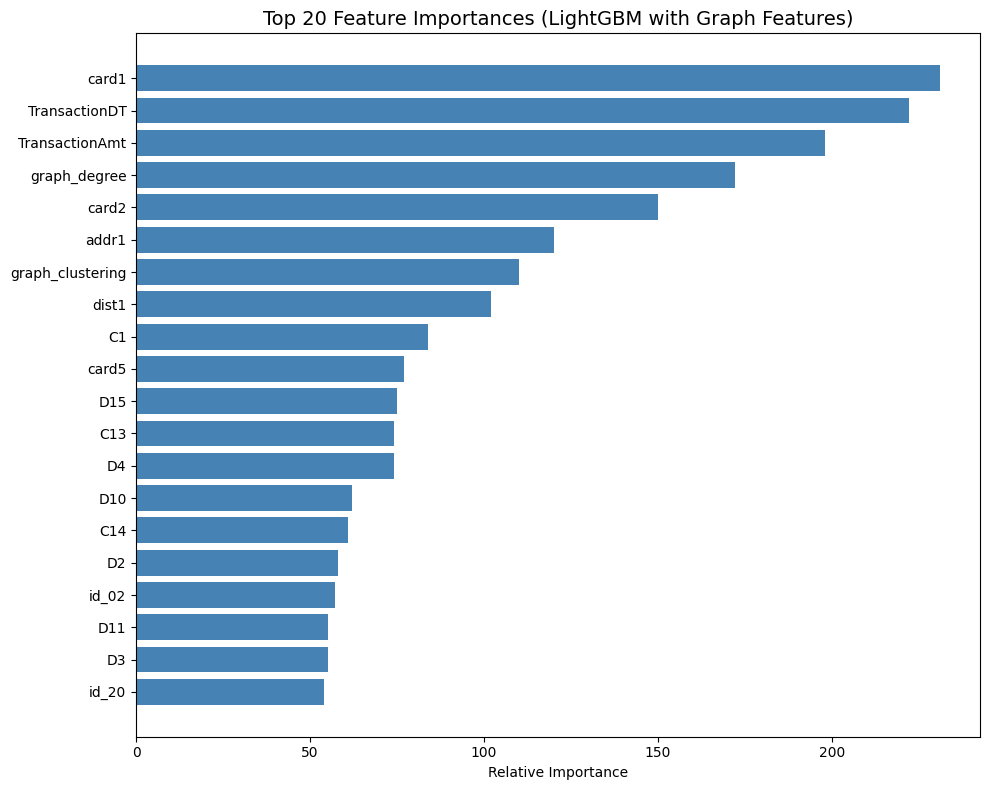

تمحفظ الصورة باسم feature_importance.png
جاري إنشاءرسم الشبكة...


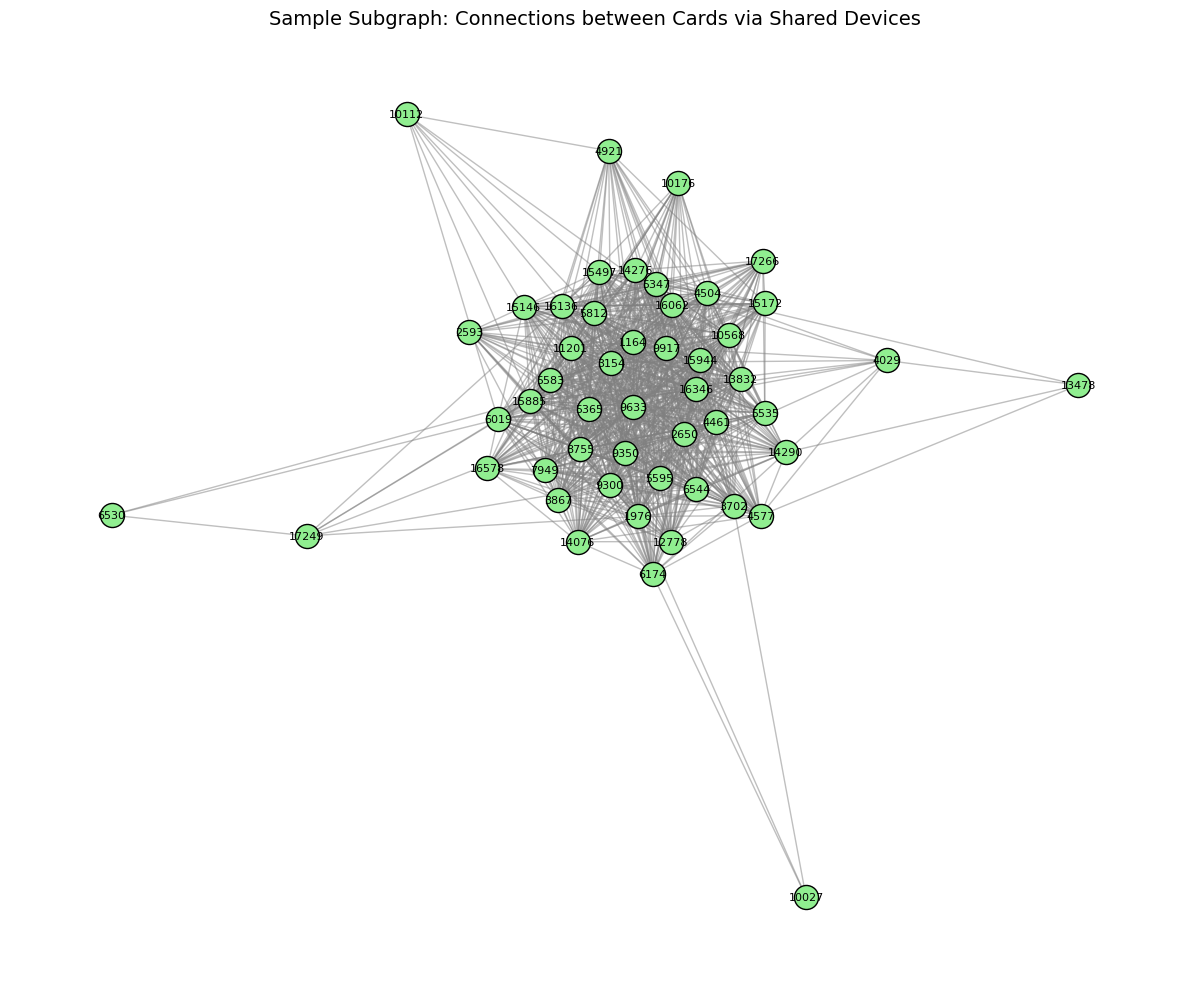

تمحفظ الصورة باسم network_graph.png


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import numpy as np

# ---------------------------------------------------------
# الرسم الأول: مخطط أهميةالميزات (Feature Importance Plot)
# ---------------------------------------------------------
print("جاري إنشاءرسم أهميةالميزات...")
plt.figure(figsize=(10, 8))

# استخراج أهم 20 ميزة
importances = clf_graph.feature_importances_
indices = np.argsort(importances)[-20:] # آخر 20 ميزة (الأعلى أهمية)

# رسم المخطط
plt.title("Top 20 Feature Importances (LightGBM with Graph Features)", fontsize=14)
plt.barh(range(len(indices)), importances[indices], color='steelblue', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel("Relative Importance")
plt.tight_layout()

# حفظ الصورة
plt.savefig('feature_importance.png', dpi=300)
plt.show()
print("تمحفظ الصورة باسم feature_importance.png")


# ---------------------------------------------------------
# الرسم الثاني: رسم بياني مصغر للشبكة (Network Subgraph)
# ---------------------------------------------------------
print("جاري إنشاءرسم الشبكة...")
plt.figure(figsize=(12, 10))

# بماأن الشبكة ضخمة جداً (214 ألفحافة)،سنأخذ جزءاًصغيراً منهاللعرض فقط
# سنأخذأول 50 عقدة (بطاقة) متصلةببعضها

nodes_to_draw = list(G.nodes())[:50]
subgraph = G.subgraph(nodes_to_draw)

# رسم الشبكة
pos = nx.spring_layout(subgraph, seed=42) # توزيع العقد

nx.draw_networkx_nodes(subgraph, pos, node_size=300, node_color='lightgreen', edgecolors='black')
nx.draw_networkx_edges(subgraph, pos, alpha=0.5, edge_color='gray')
nx.draw_networkx_labels(subgraph, pos, font_size=8)

plt.title("Sample Subgraph: Connections between Cards via Shared Devices", fontsize=14)
plt.axis('off') # إخفاءالمحاور
plt.tight_layout()

# حفظ الصورة
plt.savefig('network_graph.png', dpi=300)
plt.show()
print("تمحفظ الصورة باسم network_graph.png")
